<a href="https://colab.research.google.com/github/cintiapinho/Aulas_FATEC_PLN/blob/main/Materiais/aula%208_9/Word_Embeddings%2C_Transformers_e_Reconhecimento_de_Entidades.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sessão 08 — Word Embeddings, Transformers (BERT) e Reconhecimento de Entidades Nomeadas

**Processamento de Linguagem Natural**

Até agora, para o computador, um texto era uma **contagem de palavras** (Bag of Words, TF-IDF). Funcionou bem para classificar emoções e agrupar projetos de lei, mas tem um defeito grave: o computador não sabe que "ótimo" e "excelente" querem dizer quase a mesma coisa. Hoje vamos ver como ele aprende o **significado** das palavras e como usa isso para **encontrar nomes** de pessoas, lugares e organizações num texto.

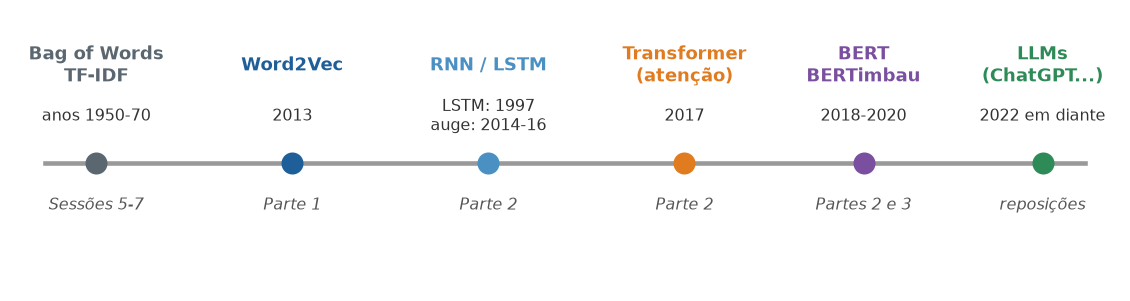

**Parte 1 — Palavras viram vetores (Word Embeddings).** O Word2Vec aprende, sozinho, que palavras usadas em contextos parecidos têm significado parecido. Vamos medir a distância entre palavras e desenhá-las num gráfico.

**Parte 2 — Redes neurais, Transformers e BERT.** O que é uma rede neural, por que as RNN/LSTM foram substituídas pelos Transformers e como o BERT entende que "banco" de praça e "banco" de dinheiro são coisas diferentes. Vamos usar o **BERTimbau**, um BERT treinado em português, e compará-lo com os classificadores da Sessão 7.

**Parte 3 — Reconhecimento de Entidades Nomeadas (NER).** Encontrar automaticamente pessoas, lugares, organizações, leis e datas num texto: primeiro com o spaCy, depois com um BERT treinado em textos jurídicos. No fim, usamos isso para **anonimizar** um texto.

> Os modelos de hoje são **baixados prontos** (já treinados por outras pessoas). Na primeira vez que cada célula roda, ela baixa o modelo; isso pode levar alguns minutos. Não precisa de GPU.

## Preparação

O Colab já vem com quase tudo instalado. Faltam duas coisas:

- `gensim`: a biblioteca do Word2Vec;
- `pt_core_news_sm`: o modelo do spaCy para português (o mesmo das Sessões 3-4).

In [ ]:
# pip install: instala a biblioteca gensim (-q = "quieto", mostra menos mensagens)
!pip install -q gensim
# baixa o modelo pequeno (sm = small) do spaCy para português
!python -m spacy download pt_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 6.7 MB/s  0:00:02
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Agora as bibliotecas e as duas planilhas da Sessão 7, que continuam no GitHub da disciplina:

- `sentimentos.xlsx`: frases rotuladas por emoção (alegria, raiva, medo, tristeza);
- `projetos_de_lei.xlsx`: ementas de projetos de lei da Câmara dos Deputados.

In [ ]:
# ===== Bibliotecas usadas na aula toda =====
import re                                   # expressões regulares, para separar as palavras
import numpy as np                          # contas com vetores e matrizes
import pandas as pd                         # tabelas (DataFrames)
import matplotlib.pyplot as plt             # gráficos
import warnings
warnings.filterwarnings("ignore")           # esconde avisos que não mudam o resultado
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()            # esconde as mensagens longas que o Hugging Face mostra ao carregar modelos

# ===== As duas planilhas (as mesmas da Sessão 7, no GitHub da disciplina) =====
pasta = "https://github.com/cintiapinho/Aulas_FATEC_PLN/raw/refs/heads/main/Materiais/aula%207_Avaliac%C3%A3o%20de%20modelos%20e%20Aprendizado%20n%C3%A3o%20supervisionado%20com%20PLN/"
arquivo = pasta + "sentimentos.xlsx"        # frases rotuladas por emoção
arquivo_pl = pasta + "projetos_de_lei.xlsx" # ementas dos projetos de lei

# drop_duplicates("frase") tira as frases repetidas; reset_index(drop=True) renumera as linhas
emocoes = pd.read_excel(arquivo).drop_duplicates("frase").reset_index(drop=True)
leis = pd.read_excel(arquivo_pl)
print("Frases com emoção:", len(emocoes), "| Projetos de lei:", len(leis))

Frases com emoção: 909 | Projetos de lei: 1599


---
# Parte 1 — Palavras viram vetores (Word Embeddings)

## 1.1 O problema: para o Bag of Words, "ótimo" não tem nada a ver com "excelente"

No Bag of Words e no TF-IDF, **cada palavra do vocabulário é uma coluna**. "ótimo" é uma coluna, "excelente" é outra, "péssimo" é outra. As colunas não têm relação nenhuma entre si: para o modelo, trocar "ótimo" por "excelente" muda o texto tanto quanto trocar "ótimo" por "péssimo".

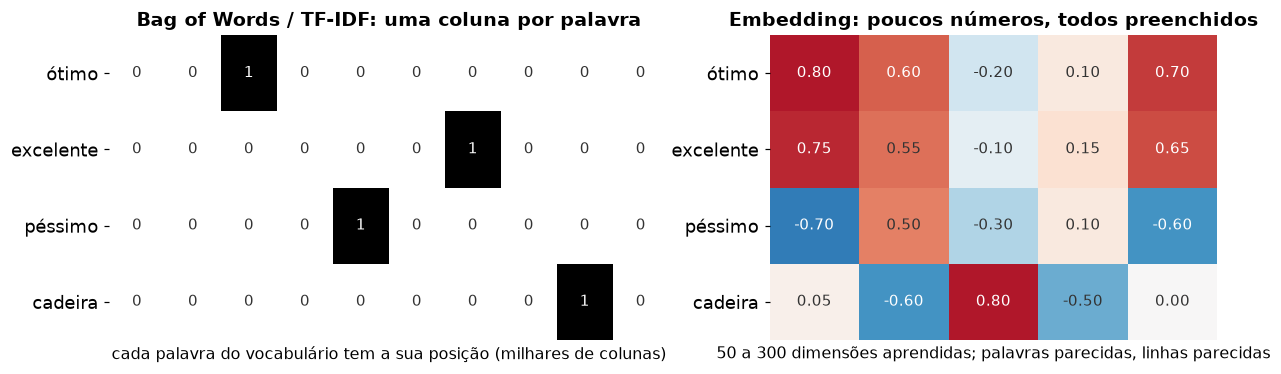

À direita está a ideia de hoje: um **embedding** (do inglês *embed*, "encaixar") representa cada palavra por uma lista pequena de números, **todos preenchidos**, e palavras de significado parecido ficam com números parecidos. Os números da figura são inventados, só para mostrar o formato; daqui a pouco vamos ver números de verdade.

Vamos confirmar o problema com o `CountVectorizer` da Sessão 5:

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

frases = ["o filme é ótimo", "o filme é excelente", "o filme é péssimo"]

contagem = CountVectorizer()              # Bag of Words: uma coluna por palavra
X = contagem.fit_transform(frases)        # cada frase vira uma linha de contagens
# toarray() mostra a matriz completa (com os zeros); get_feature_names_out() dá o nome das colunas
print(pd.DataFrame(X.toarray(), columns=contagem.get_feature_names_out(), index=frases), "\n")

# cosine_similarity compara cada frase com todas as outras: 1 = iguais, 0 = nada em comum
pd.DataFrame(cosine_similarity(X), index=frases, columns=frases).round(2)

                     excelente  filme  péssimo  ótimo
o filme é ótimo              0      1        0      1
o filme é excelente          1      1        0      0
o filme é péssimo            0      1        1      0 



,o filme é ótimo,o filme é excelente,o filme é péssimo
o filme é ótimo,1.0,0.5,0.5
o filme é excelente,0.5,1.0,0.5
o filme é péssimo,0.5,0.5,1.0


A frase com "ótimo" está **exatamente tão perto** da frase com "excelente" (0,5) quanto da frase com "péssimo" (0,5). O Bag of Words só enxerga a palavra igual ("filme"; o `CountVectorizer` ignora palavras de uma letra, como "o" e "é"). A única palavra que muda o sentido é tratada como um símbolo qualquer.

Nas Sessões 5-7 isso foi contornado com **muitos exemplos**: o classificador acaba vendo "ótimo" e "excelente" em frases de alegria e aprende os dois separadamente. Mas uma palavra que nunca apareceu no treino (por exemplo, "espetacular") não ajuda em nada.

## 1.2 A ideia: "diga-me com quem andas e te direi quem és"

Como o computador poderia descobrir o significado de uma palavra sem dicionário? A resposta vem da linguística, dos anos 1950, e se chama **hipótese distribucional**: palavras que aparecem nos **mesmos contextos** costumam ter **significados parecidos**. A frase famosa é do linguista J. R. Firth (1957): *"You shall know a word by the company it keeps"* ("você conhece uma palavra pelas companhias dela").

Teste com você mesmo: que palavras cabem no espaço?

> *Tomei um copo de ______ gelado.*

Suco, refrigerante, chá, leite... Você não pensou em "cadeira" nem em "correr". As palavras que cabem no mesmo buraco são justamente as de significado parecido.

Vamos ver os contextos de duas palavras nas ementas dos projetos de lei. A função abaixo mostra cada vez que a palavra aparece, com as palavras em volta (isso se chama **concordância**, e é o que um linguista faz à mão):

In [ ]:
def contextos(palavra, textos, janela=4, n=6):
    achados = []                                        # aqui guardamos os trechos encontrados
    for texto in textos:                                # percorre cada texto
        tokens = re.findall(r"\w+", texto.lower())      # \w+ pega cada palavra; lower() deixa tudo minúsculo
        for i, t in enumerate(tokens):                  # enumerate dá a posição i e a palavra t
            if t == palavra:                            # achou a palavra procurada
                # tokens[a:b] pega as palavras da posição a até b-1; max(0, ...) evita posição negativa
                esquerda = " ".join(tokens[max(0, i - janela):i])
                direita = " ".join(tokens[i + 1:i + 1 + janela])
                # :>38 alinha o texto da esquerda à direita, em 38 caracteres, para a palavra ficar numa coluna só
                achados.append(f"{esquerda:>38}  [{t}]  {direita}")
    return achados[:n]                                  # devolve só os n primeiros

for palavra in ["escolas", "creches"]:            # duas palavras para comparar
    print(f"===== {palavra} =====")
    for linha in contextos(palavra, leis["ementa"]):    # procura nas ementas
        print(linha)

===== escolas =====
               da linguagem neutra nas  [escolas]  públicas e privadas do
               escolha dos gestores de  [escolas]  públicas
        referentes ao fardamento pelas  [escolas]  públicas
               externas e internas nas  [escolas]  e creches públicas e
               de segurança armada nas  [escolas]  da rede pública e
            audição aos estudantes das  [escolas]  públicas
===== creches =====
               na educação infantil em  [creches]  da rede particular de
                internas nas escolas e  [creches]  públicas e privadas no
     contra templos religiosos escolas  [creches]  e hospitais
                    espera de vagas em  [creches]  
               educação infantil e das  [creches]  públicas
                ampliação da oferta de  [creches]  pnaoc e dá outras


As duas palavras andam com as mesmas companhias: "públicas", "privadas", "particular", "rede", "educação infantil", e uma aparece até ao lado da outra ("nas escolas e creches públicas"). Um computador que só olhasse os vizinhos já desconfiaria que "escolas" e "creches" são palavras do mesmo tipo, sem ninguém dizer o que elas significam.

## 1.3 Word2Vec: o próprio texto vira o rótulo

No fim da Sessão 7 ficou uma pergunta: *e se o próprio texto virasse o rótulo?* O **Word2Vec** (Mikolov e colegas, Google, 2013) faz exatamente isso. Ele inventa uma tarefa de adivinhação que não precisa de ninguém rotulando nada:

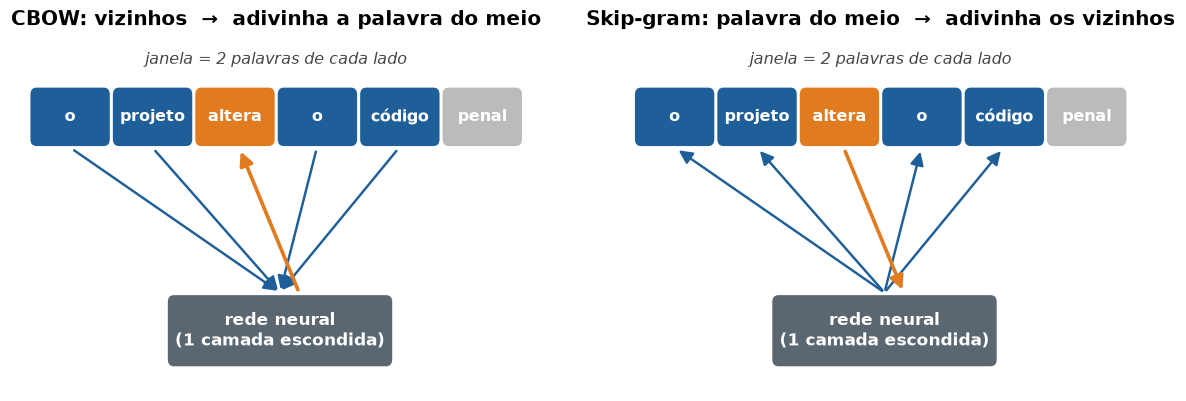

- **CBOW** (*continuous bag of words*): recebe os vizinhos e tenta adivinhar a palavra do meio;
- **Skip-gram**: recebe a palavra do meio e tenta adivinhar cada vizinho.

A **janela** diz quantos vizinhos contam de cada lado.

O truque é que **ninguém quer saber das adivinhações**. Para acertar os vizinhos, a rede precisa guardar, para cada palavra, uma lista de números (os **pesos** da camada escondida). Palavras que aparecem com os mesmos vizinhos acabam com listas parecidas, porque servem para adivinhar as mesmas coisas. No fim do treino, jogamos a rede fora e ficamos só com essas listas: **são os embeddings**.

Isso é **aprendizado auto-supervisionado**: é supervisionado (tem entrada e rótulo), mas o rótulo sai do próprio texto, de graça. Por isso dá para treinar com bilhões de palavras.

Veja os exemplos de treino que o skip-gram tira de **uma única frase**:

In [ ]:
frase = "o projeto altera o código penal".split()   # split() separa a frase nos espaços
janela = 2                                          # 2 vizinhos de cada lado

pares = []                                          # cada par é (entrada, rótulo) para a rede
for i, centro in enumerate(frase):                  # percorre cada palavra, com a posição i
    # range(início, fim) percorre as posições vizinhas; max/min evitam sair da frase
    for j in range(max(0, i - janela), min(len(frase), i + janela + 1)):
        if j != i:                                  # a palavra não é vizinha dela mesma
            pares.append((centro, frase[j]))        # entrada = palavra do meio; rótulo = o vizinho

print("Uma frase de 6 palavras gerou", len(pares), "exemplos de treino, sem ninguém rotular nada.")
pd.DataFrame(pares, columns=["entrada (palavra do meio)", "rótulo (vizinho)"]).head(10)

Uma frase de 6 palavras gerou 18 exemplos de treino, sem ninguém rotular nada.


,entrada (palavra do meio),rótulo (vizinho)
0,o,projeto
1,o,altera
2,projeto,o
3,projeto,altera
4,projeto,o
5,altera,o
6,altera,projeto
7,altera,o
8,altera,código
9,o,projeto


Com um livro inteiro são milhões de pares; com a Wikipédia, bilhões. Cada par empurra um pouquinho os números da palavra de entrada na direção que ajuda a acertar o vizinho.

## 1.4 Treinando um Word2Vec com as ementas da Câmara

Vamos treinar o nosso próprio Word2Vec com as 1.599 ementas da Sessão 7. O `gensim` faz todo o trabalho; só precisamos entregar os textos já separados em palavras.

In [ ]:
from gensim.models import Word2Vec

# cada ementa vira uma lista de palavras minúsculas (o gensim espera uma lista de listas)
sentencas = [re.findall(r"\w+", ementa.lower()) for ementa in leis["ementa"]]
print("Total de palavras no corpus:", sum(len(s) for s in sentencas))

w2v = Word2Vec(
    sentencas,
    vector_size=50,     # cada palavra vira uma lista de 50 números
    window=5,           # janela: 5 vizinhos de cada lado
    min_count=3,        # ignora palavras que aparecem menos de 3 vezes (pouca informação)
    sg=1,               # sg=1 -> skip-gram; sg=0 -> CBOW
    epochs=50,          # passa 50 vezes pelo corpus (corpus pequeno precisa de mais voltas)
    seed=42,            # semente: o resultado sai sempre igual
    workers=1,          # 1 processador só: também para o resultado sair sempre igual
)
print("Palavras no vocabulário:", len(w2v.wv))     # wv = "word vectors", os vetores aprendidos

# o vetor da palavra "penal": 50 números; mostramos os 10 primeiros, com 3 casas decimais
print('Vetor de "penal" (10 primeiros de 50 números):', w2v.wv["penal"][:10].round(3))

Total de palavras no corpus: 45678
Palavras no vocabulário: 1573
Vetor de "penal" (10 primeiros de 50 números): [ 0.265  0.359 -0.17  -0.246 -0.666  1.064 -0.386 -0.454 -0.915  0.448]


Os números, sozinhos, não querem dizer nada (não existe uma "coluna de crime"). O que importa é **comparar** vetores: o método `most_similar` procura as palavras com os vetores mais parecidos.

In [ ]:
for palavra in ["penal", "trânsito", "crime", "escolas", "trabalhador", "saúde"]:                                  # algumas palavras dos 6 temas
    vizinhas = w2v.wv.most_similar(palavra, topn=6)               # as 6 palavras de vetor mais parecido
    # cada item é (palavra, similaridade); :.2f mostra a similaridade com 2 casas
    print(f"{palavra:>12} →", ", ".join(f"{w} ({s:.2f})" for w, s in vizinhas))

       penal → 1940 (0.75), código (0.70), criminalizar (0.67), 848 (0.67), simples (0.65), afastar (0.65)
    trânsito → pontuação (0.77), transito (0.77), 1997 (0.76), brasileiro (0.70), 503 (0.69), ctb (0.67)
       crime → qualificadora (0.78), importunação (0.78), feminicídio (0.74), qualificado (0.73), simples (0.73), perseguição (0.72)
     escolas → creches (0.83), particulares (0.73), paz (0.71), enfrentamento (0.70), neutra (0.69), públicas (0.68)
 trabalhador → pagamento (0.67), férias (0.66), empregador (0.65), desemprego (0.65), salário (0.62), ausência (0.62)
       saúde → mama (0.65), sus (0.64), cirurgia (0.63), credenciamento (0.62), conveniada (0.62), ambulatorial (0.62)


Repare no que o modelo aprendeu só olhando vizinhos, em 45 mil palavras:

- **"penal" está perto de "código", "1940" e "848".** O Código Penal é o Decreto-Lei nº **2.848**, de **1940**. Ninguém contou isso ao modelo; ele só viu que esses números aparecem sempre perto de "penal".
- **"trânsito" está perto de "1997", "503" e "ctb".** O Código de Trânsito Brasileiro (CTB) é a Lei nº 9.**503**, de **1997**. Ele também juntou "trânsito" com "transito", escrito sem acento em algumas ementas.
- **"crime"** está perto de "qualificadora", "importunação", "feminicídio", "perseguição": vocabulário de direito penal. **"escolas"** está perto de "creches", e **"trabalhador"** de "férias", "empregador", "salário".

Mas também aparecem vizinhos sem sentido ("penal" com "simples" e "afastar"; "escolas" com "paz"). O corpus é **minúsculo** para um Word2Vec: são 45 mil palavras e um vocabulário de só 1.573. O modelo também só conhece o mundo das ementas: não sabe o que é "cachorro" nem "felicidade".

## 1.5 Um embedding treinado com 1,4 bilhão de palavras

Treinar com bilhões de palavras leva horas e precisa de muita memória. Mas não precisamos: o **NILC** (Núcleo Interinstitucional de Linguística Computacional, da USP de São Carlos) treinou e publicou embeddings de português com um corpus de cerca de **1,4 bilhão de palavras**, juntando 17 fontes (Wikipédia, notícias, livros, legendas de filmes...), tanto do português do Brasil quanto de Portugal (Hartmann e colegas, 2017).

Vamos usar o Word2Vec skip-gram com 50 números por palavra, que é o menor deles. Ele está no Hugging Face, um site que guarda modelos prontos (o mesmo de onde vamos baixar o BERT). O download tem cerca de 190 MB.

In [ ]:
from huggingface_hub import hf_hub_download       # baixa arquivos do Hugging Face
from safetensors.numpy import load_file           # lê o formato em que os vetores foram guardados
from gensim.models import KeyedVectors            # a "tabela de vetores" do gensim (sem a rede de treino)

repositorio = "nilc-nlp/word2vec-skip-gram-50d"
# hf_hub_download baixa o arquivo (só na primeira vez) e devolve o caminho dele no computador
caminho_vetores = hf_hub_download(repositorio, "embeddings.safetensors")
caminho_vocab = hf_hub_download(repositorio, "vocab.txt")

matriz = load_file(caminho_vetores)["embeddings"]   # matriz: uma linha por palavra, 50 colunas
with open(caminho_vocab, encoding="utf-8") as f:    # vocab.txt: uma palavra por linha, na ordem da matriz
    vocabulario = [linha.rstrip("\n") for linha in f]  # rstrip("\n") tira a quebra de linha do fim

nilc = KeyedVectors(vector_size=matriz.shape[1])    # tabela vazia para vetores de 50 números
nilc.add_vectors(vocabulario, matriz)               # junta cada palavra com a sua linha da matriz
print("Palavras:", len(nilc), "| números por palavra:", nilc.vector_size)

Palavras: 929606 | números por palavra: 50


In [ ]:
for palavra in ["cachorro", "rei", "deputado", "espetacular", "feliz"]:                                     # palavras do dia a dia
    vizinhas = nilc.most_similar(palavra, topn=15)
    print(f"{palavra:>10} →", ", ".join(f"{w} ({s:.2f})" for w, s in vizinhas))

  cachorro → cão (0.91), cãozinho (0.90), gambá (0.89), filhote (0.88), gato (0.88), cachorrinho (0.88), mendigo (0.87), bandido (0.87), capanga (0.86), boneco (0.86), gorila (0.86), bichinho (0.85), lenhador (0.85), ladrão (0.85), chimpanzé (0.85)
       rei → imperador (0.94), príncipe (0.94), tsar (0.91), ex-rei (0.91), déspota (0.90), czar (0.90), sigismundo (0.90), protoestrator (0.89), sebastocrator (0.89), patriarca (0.89), arquiduque (0.89), lugar-tenente (0.89), príncipe-eleitor (0.89), herdeiro (0.89), ex-imperador (0.89)
  deputado → senador (0.90), ex-deputado (0.89), psdb (0.88), ptb (0.88), vice-governador (0.88), ppb (0.87), vereador (0.86), priante (0.86), prefeito (0.86), pmdb (0.86), pfl (0.85), psb (0.85), vice-prefeito (0.85), slonikarz (0.84), pdt (0.84)
espetacular → sensacional (0.82), emocionante (0.80), empolgante (0.80), eletrizante (0.79), inesquecível (0.75), memorável (0.75), irretocável (0.75), fenomenal (0.73), incrível (0.73), arrasador (0.71), maracanaç

Com 1,4 bilhão de palavras, o resultado é outro:

- **cachorro** → cão, cãozinho, filhote, gato, cachorrinho (sinônimos, diminutivos e outros bichos de estimação);
- **rei** → imperador, príncipe, czar;
- **deputado** → senador, vice-governador, e as siglas de partidos (psdb, ptb, ppb). O modelo aprendeu com muitas notícias de política;
- **espetacular** → sensacional, emocionante, empolgante. É justamente a palavra da seção 1.1 que o classificador da Sessão 7 nunca tinha visto.

E uma surpresa: o vizinho mais próximo de **feliz** é **triste**. Já vamos entender por quê.

(Detalhe: nesse embedding todo o texto foi passado para minúsculas, e por isso usamos "brasil" e não "Brasil".)

## 1.6 Similaridade de cosseno, calculada na mão

O `most_similar` usa a **similaridade de cosseno**, a mesma da Sessão 7. Ela mede o **ângulo** entre dois vetores:

$$\text{cosseno}(a, b) = \frac{a \cdot b}{\|a\| \times \|b\|}$$

- em cima, o **produto escalar**: multiplica posição por posição e soma tudo;
- embaixo, o **tamanho** (norma) de cada vetor: raiz da soma dos quadrados.

O resultado vai de −1 a 1:

- **perto de 1**: os vetores apontam para o mesmo lado (palavras parecidas);
- **perto de 0**: não têm relação;
- **negativo**: apontam para lados opostos.

Vamos fazer a conta com o NumPy e conferir com o gensim:

In [ ]:
def cosseno(a, b):
    produto = np.dot(a, b)                  # produto escalar: soma de a[i] * b[i]
    tamanho_a = np.linalg.norm(a)           # norm = raiz da soma dos quadrados (o "tamanho" do vetor)
    tamanho_b = np.linalg.norm(b)
    return produto / (tamanho_a * tamanho_b)

pares = [("alegria", "felicidade"), ("ótimo", "excelente"), ("ótimo", "péssimo"), ("feliz", "triste"), ("ótimo", "cadeira")]
linhas = []                                                   # uma linha da tabela por par de palavras
for p1, p2 in pares:                                          # percorre cada par
    linhas.append({
        "palavra 1": p1, "palavra 2": p2,
        "cosseno (na mão)": round(float(cosseno(nilc[p1], nilc[p2])), 3),   # nilc[p] devolve o vetor da palavra
        "cosseno (gensim)": round(float(nilc.similarity(p1, p2)), 3),       # o mesmo cálculo, pronto
    })
pd.DataFrame(linhas)

,palavra 1,palavra 2,cosseno (na mão),cosseno (gensim)
0,alegria,felicidade,0.869,0.869
1,ótimo,excelente,0.570,0.570
2,ótimo,péssimo,0.743,0.743
3,feliz,triste,0.868,0.868
4,ótimo,cadeira,0.031,0.031


As duas colunas dão o mesmo valor: o gensim faz exatamente a conta da fórmula.

Agora repare nos números:

| par | cosseno | o que mostra |
|---|---|---|
| alegria × felicidade | 0,87 | sinônimos: bem perto |
| ótimo × cadeira | 0,03 | nada a ver: perto de zero |
| ótimo × excelente | 0,57 | perto, como esperado |
| **ótimo × péssimo** | **0,74** | **mais perto do que "excelente"!** |
| **feliz × triste** | **0,87** | **antônimos, quase colados** |

Isso parece um defeito, mas é a hipótese distribucional funcionando à risca. "Ótimo" e "péssimo" aparecem **nos mesmos lugares**: "o filme foi ___", "o atendimento estava ___". O Word2Vec aprende que as duas são "o mesmo tipo de palavra" (adjetivos de avaliação), mas **não aprende a direção** (bom ou ruim), porque o contexto em volta é igual.

**Consequência prática:** um embedding sozinho não resolve análise de sentimento. Ele ajuda a juntar "ótimo" com "excelente" e "espetacular", mas ainda precisamos de **exemplos rotulados** para o classificador aprender qual lado é positivo.

## 1.7 Vendo os vetores: de 50 dimensões para 2

Não dá para desenhar 50 dimensões. O **PCA** (análise de componentes principais) espreme os 50 números em 2, tentando perder o mínimo de informação, e aí dá para fazer um gráfico. Escolhemos palavras de quatro grupos e vemos se o embedding as separa **sem ninguém dizer quais são os grupos**:

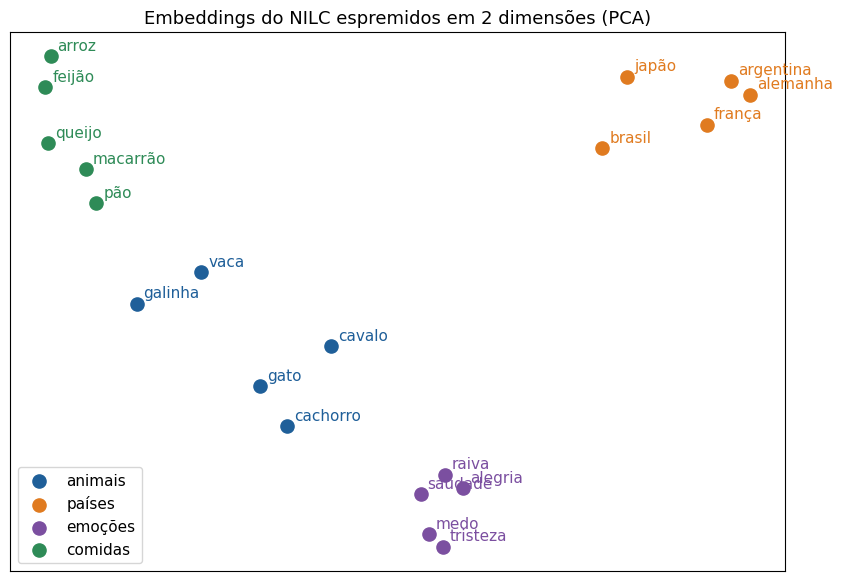

In [ ]:
from sklearn.decomposition import PCA

grupos = {                                                        # 4 grupos, 5 palavras cada
    "animais": ["cachorro", "gato", "cavalo", "vaca", "galinha"],
    "países": ["brasil", "argentina", "frança", "japão", "alemanha"],
    "emoções": ["alegria", "tristeza", "raiva", "medo", "saudade"],
    "comidas": ["arroz", "feijão", "macarrão", "pão", "queijo"],
}

palavras = [p for lista in grupos.values() for p in lista]       # junta todas as palavras numa lista só
vetores = np.array([nilc[p] for p in palavras])                   # uma linha de 50 números por palavra
pontos = PCA(n_components=2, random_state=42).fit_transform(vetores)  # de 50 para 2 números por palavra

cores = ["#1f5f99", "#e07b20", "#7b4fa0", "#2e8b57"]
fig, ax = plt.subplots(figsize=(10, 7))
inicio = 0                                                         # posição da 1ª palavra do grupo na lista
for (nome, lista), cor in zip(grupos.items(), cores):             # zip junta cada grupo com uma cor
    fim = inicio + len(lista)                                      # posição logo depois da última palavra do grupo
    ax.scatter(pontos[inicio:fim, 0], pontos[inicio:fim, 1], s=90, color=cor, label=nome)
    for p, (x, y) in zip(lista, pontos[inicio:fim]):               # escreve cada palavra ao lado do seu ponto
        ax.annotate(p, (x, y), xytext=(5, 4), textcoords="offset points", fontsize=11, color=cor)
    inicio = fim                                                   # o próximo grupo começa onde este terminou
ax.set_title("Embeddings do NILC espremidos em 2 dimensões (PCA)", fontsize=13)
ax.legend(fontsize=11)
ax.set_xticks([]); ax.set_yticks([])                               # os eixos do PCA não têm unidade, então escondemos
plt.show()

Sem saber nada sobre os grupos, o embedding colocou cada um num canto: **países** juntos, **comidas** juntas, **emoções** juntas, **animais** juntos.

Repare em dois detalhes:

- **"vaca" e "galinha"** ficaram no meio do caminho entre os animais e as comidas. Faz sentido: nos textos, elas aparecem tanto no pasto quanto no prato.
- **"cachorro" e "gato"** ficaram mais longe da comida e mais perto das emoções: são animais de estimação.

Lembre que o PCA espreme 50 dimensões em 2, então sempre se perde alguma coisa. Duas palavras que parecem coladas no gráfico podem estar mais longe nas 50 dimensões.

## 1.8 Cuidado: o embedding aprende também os preconceitos do texto

O Word2Vec aprende **o que está escrito**, e isso inclui os estereótipos da sociedade. Uma forma simples de ver isso: medir o cosseno (seção 1.6) de algumas palavras com "ele" e com "ela".

In [ ]:
# o cosseno de algumas palavras com "ele" e com "ela"
palavras_teste = ["beleza", "dança", "cozinha", "costura", "futebol", "liderança", "engenharia"]
vies = pd.DataFrame({
    "perto de 'ele'": [nilc.similarity(p, "ele") for p in palavras_teste],   # cosseno com "ele"
    "perto de 'ela'": [nilc.similarity(p, "ela") for p in palavras_teste],   # cosseno com "ela"
}, index=palavras_teste)
vies["diferença (ela − ele)"] = vies["perto de 'ela'"] - vies["perto de 'ele'"]   # positivo = mais perto de "ela"
vies.round(3)

,perto de 'ele',perto de 'ela',diferença (ela − ele)
beleza,0.117,0.303,0.187
dança,0.066,0.206,0.140
cozinha,0.089,0.170,0.081
costura,0.036,0.087,0.050
futebol,0.034,0.010,-0.024
liderança,0.145,0.116,-0.028
engenharia,0.023,-0.016,-0.039


"Beleza", "dança", "cozinha" e "costura" estão mais perto de **"ela"**; "futebol", "liderança" e "engenharia" estão mais perto de **"ele"**. As diferenças são pequenas, mas vão sempre na direção dos estereótipos.

O modelo não "acha" nada: ele reproduz como essas palavras aparecem nos textos que leu. Isso vira um problema real quando um sistema usa esses vetores para tomar decisões, por exemplo para ordenar currículos ou recomendar vagas. Esse fenômeno foi mostrado num artigo famoso em inglês, com o título *"Man is to Computer Programmer as Woman is to Homemaker?"* ("homem está para programador assim como mulher está para dona de casa?", Bolukbasi e colegas, 2016). Os modelos maiores, como BERT e os LLMs, também aprendem esses vieses, e testar isso faz parte de avaliar um modelo.

## 1.9 O limite do Word2Vec: uma palavra, um vetor só

"Banco" pode ser de sentar ou de guardar dinheiro. "Manga" pode ser fruta ou parte da camisa. Mas o Word2Vec dá **um único vetor** para cada palavra, que acaba sendo uma mistura dos significados:

In [ ]:
for palavra in ["banco", "manga"]:                    # duas palavras com mais de um significado
    vizinhas = nilc.most_similar(palavra, topn=10)
    print(f"{palavra:>6} →", ", ".join(w for w, s in vizinhas))

 banco → bndes, bnb, bamerindus, citigroup, bankboston, itaú-bba, banrisul, bc, santander, bb
 manga → camiseta, cola, jaqueta, bolacha, maçã, pastel, capa, salsicha, cereja, chocolate


- **banco** → bndes, bnb, bamerindus, citigroup, santander... Só sobrou o sentido de **dinheiro**, porque nos textos (muitas notícias) "banco" quase sempre é instituição financeira. O banco da praça desapareceu.
- **manga** → camiseta, jaqueta, capa (**roupa**) misturadas com maçã, cereja, bolacha, pastel (**comida**). Um único vetor ficou no meio do caminho entre os dois significados.

Para resolver isso, o vetor precisa **mudar conforme a frase**: em "sentei no banco da praça" e em "paguei o boleto no banco", a palavra "banco" deveria receber vetores diferentes. É isso que o BERT faz, na Parte 2.

---
# Parte 2 — Redes neurais, Transformers e BERT

## 2.1 Redes neurais em um minuto

A peça básica é o **neurônio artificial**. Ele recebe alguns números, multiplica cada um por um **peso**, soma tudo e passa o resultado por uma **função de ativação** (por exemplo, a sigmoide, que transforma qualquer número num valor entre 0 e 1):

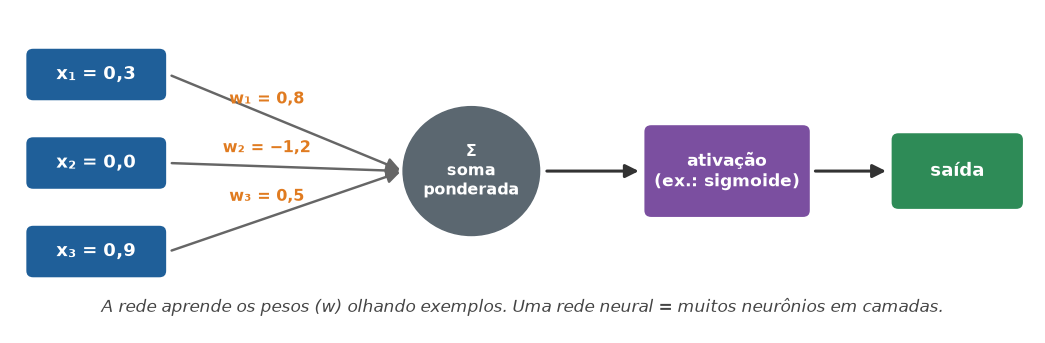

Você já usou isso sem perceber: o `SGDClassifier` e a regressão logística da Sessão 7 são **um neurônio só**. Os pesos que vimos na seção 1.13 da Sessão 7 (as palavras que mais puxam para cada emoção) são exatamente os *w* da figura.

Uma **rede neural** empilha muitos neurônios em **camadas**: a saída de uma camada é a entrada da próxima. Com várias camadas (por isso *deep learning*, aprendizado "profundo"), a rede consegue aprender padrões muito mais complicados do que um neurônio sozinho. O treino é o mesmo de sempre: mostrar exemplos, medir o erro e ajustar os pesos um pouquinho para errar menos.

O Word2Vec da Parte 1 é uma rede bem rasa (uma camada escondida). O BERT, que vamos usar daqui a pouco, tem 12 camadas e cerca de 110 milhões de pesos.

## 2.2 RNN e LSTM: ler uma palavra de cada vez

Texto é uma **sequência**: a ordem das palavras importa ("o cachorro mordeu o homem" ≠ "o homem mordeu o cachorro"). A primeira solução das redes neurais foi ler como a gente lê, **uma palavra por vez**, carregando uma "memória" do que já foi lido:

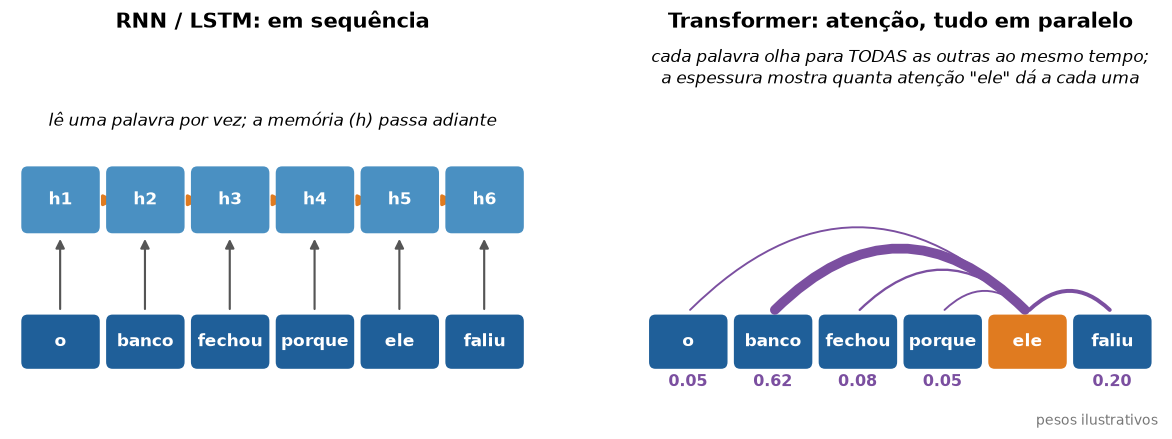

- **RNN** (rede neural recorrente): a cada palavra, junta a palavra nova com a memória (h) e passa a memória adiante.
- **LSTM** (*long short-term memory*, 1997): uma RNN com "portões" que decidem o que guardar e o que esquecer, para lembrar por mais tempo.

Foram o estado da arte entre 2014 e 2017 (tradução automática, teclados que sugerem a próxima palavra). Mas têm dois problemas:

1. **Esquecem**: numa frase longa, o começo vai se apagando da memória até o fim.
2. **São lentas**: a palavra 10 só pode ser lida depois da 9, que depois da 8... não dá para fazer tudo ao mesmo tempo, e treinar com bilhões de palavras fica caro demais.

## 2.3 Transformer: atenção, tudo ao mesmo tempo

Em 2017, um artigo do Google com o título *Attention Is All You Need* ("atenção é tudo de que você precisa") propôs o **Transformer**. A ideia está no lado direito da figura acima: em vez de ler em fila, **cada palavra olha para todas as outras ao mesmo tempo** e decide em quais prestar mais atenção.

Na frase *"o banco fechou porque ele faliu"*, para entender "ele" é preciso saber a quem se refere. O mecanismo de **atenção** calcula um peso entre "ele" e cada palavra da frase. Se o modelo estiver bem treinado, o peso maior vai para "banco". O vetor de "ele" passa a ser uma **mistura** dos vetores das outras palavras, na proporção desses pesos. (Os números da figura são ilustrativos.)

Isso resolve os dois problemas da LSTM:

1. **Não esquece**: a primeira palavra está a um passo da última, não importa o tamanho da frase.
2. **É rápido**: todas as palavras são processadas em paralelo, o que combina com placas de vídeo (GPUs). Isso permitiu treinar com quantidades gigantescas de texto.

Um Transformer empilha várias camadas de atenção. A cada camada, o vetor de cada palavra fica um pouco mais "contextualizado".

## 2.4 BERT e GPT: dois jeitos de usar o Transformer

Os dois são Transformers treinados de forma **auto-supervisionada**, como o Word2Vec: o rótulo sai do próprio texto. A diferença é a tarefa de adivinhação:

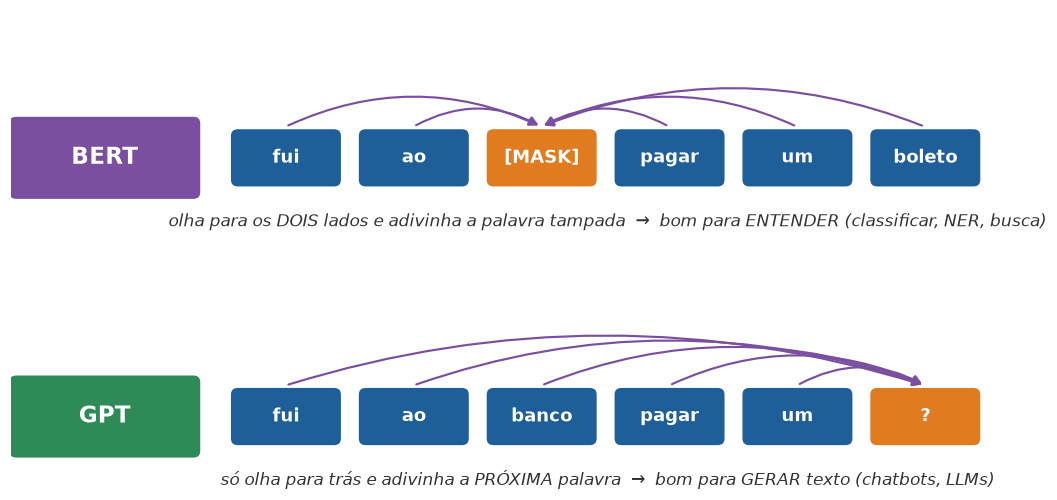

| | **BERT** (Google, 2018) | **GPT** (OpenAI, 2018 em diante) |
|---|---|---|
| Tarefa de treino | tampa 15% das palavras (`[MASK]`) e adivinha quais eram | adivinha a **próxima** palavra |
| Olha para | os dois lados da palavra | só para trás |
| Bom para | **entender**: classificar, encontrar entidades, buscar | **gerar** texto: chatbots, resumos, tradução |
| Na disciplina | hoje | aulas de reposição (LLMs, chat, RAG, agentes) |

Hoje vamos usar o BERT. Os modelos tipo GPT (ChatGPT, Gemini, Claude, Llama...) são os LLMs que vocês estão vendo nas aulas de reposição.

## 2.5 BERTimbau: um BERT que leu português

O BERT original foi treinado em inglês. O **BERTimbau** (Souza, Nogueira e Lotufo, 2020) é um BERT treinado do zero com o **brWaC**, um corpus enorme de páginas da web brasileiras. Ele foi feito pela NeuralMind, uma empresa de Campinas, e está no Hugging Face com o nome `neuralmind/bert-base-portuguese-cased` (*base* = o tamanho menor, 12 camadas; *cased* = diferencia maiúsculas de minúsculas).

Antes de tudo, o BERT corta o texto em **pedaços** (*tokens*). Ele não usa um vocabulário de palavras inteiras: usa cerca de 30 mil pedaços. Palavras comuns são um pedaço só; palavras raras são quebradas em pedaços menores, marcados com `##`. Assim **nenhuma palavra fica de fora**, nem as que ele nunca viu (lembra da palavra "espetacular" da seção 1.1?).

In [ ]:
from transformers import AutoTokenizer

nome_bert = "neuralmind/bert-base-portuguese-cased"
tokenizador = AutoTokenizer.from_pretrained(nome_bert)     # baixa o "cortador de texto" do BERTimbau

for palavra in ["deputados", "linguagem", "excelente", "espetacular", "inconstitucionalidade", "anticorrupção", "Fatec", "WhatsApp"]:                       # palavras comuns e raras
    # tokenize() mostra os pedaços; "##" indica que o pedaço continua o anterior, sem espaço
    print(f"{palavra:>24} → {tokenizador.tokenize(palavra)}")

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

               deputados → ['deputados']
               linguagem → ['linguagem']
               excelente → ['excelente']
             espetacular → ['espe', '##tacular']
   inconstitucionalidade → ['incons', '##titu', '##cional', '##idade']
           anticorrupção → ['antic', '##orr', '##up', '##ção']
                   Fatec → ['Fa', '##tec']
                WhatsApp → ['Wh', '##ats', '##Ap', '##p']


- Palavras comuns ("deputados", "linguagem", "excelente") são **um token só**.
- Palavras menos comuns são quebradas: "inconstitucionalidade" vira `incons` + `##titu` + `##cional` + `##idade`. Até "espetacular" vira `espe` + `##tacular`.
- Nomes que ele nunca viu também são cortados, como "Fatec" (`Fa` + `##tec`) e "WhatsApp".

Nenhuma palavra fica sem representação, e o BERT junta o significado dos pedaços olhando a frase toda.

## 2.6 O BERT preenchendo lacunas

Esta é a tarefa com que o BERT foi treinado: adivinhar a palavra tampada com `[MASK]`. O `pipeline` do Hugging Face já faz tudo (cortar em tokens, passar pela rede e transformar a saída em palavras):

In [ ]:
from transformers import pipeline

# "fill-mask" = preencher a máscara; na primeira vez baixa o BERTimbau (cerca de 400 MB)
preencher = pipeline("fill-mask", model=nome_bert)

frases_mask = [
    "Tinha uma [MASK] no meio do caminho.",
    "O projeto altera o Código [MASK] para aumentar a pena de homicídio.",
    "Ela foi ao banco pagar uma [MASK].",
    "Fiquei muito [MASK] com a notícia da promoção.",
    "Fiquei muito [MASK] com a notícia da demissão.",
]
for frase in frases_mask:                                     # percorre as frases com [MASK]
    palpites = preencher(frase, top_k=5)                      # top_k=5: os 5 palpites mais prováveis
    # cada palpite é um dicionário; "token_str" é a palavra e "score" é a probabilidade
    print(frase)
    print("   →", ", ".join(f"{p['token_str']} ({p['score']:.2f})" for p in palpites))

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

Tinha uma [MASK] no meio do caminho.
   → pedra (0.14), árvore (0.06), estrada (0.06), casa (0.03), cruz (0.03)
O projeto altera o Código [MASK] para aumentar a pena de homicídio.
   → Penal (0.99), penal (0.01), Civil (0.00), Eleitoral (0.00), Brasileiro (0.00)
Ela foi ao banco pagar uma [MASK].
   → dívida (0.70), conta (0.11), taxa (0.03), prestação (0.03), pensão (0.01)
Fiquei muito [MASK] com a notícia da promoção.
   → feliz (0.92), animado (0.03), triste (0.02), surpresa (0.01), animada (0.01)
Fiquei muito [MASK] com a notícia da demissão.
   → triste (0.47), feliz (0.45), surpresa (0.04), animado (0.01), preocupado (0.01)


- **"Tinha uma ___ no meio do caminho"** → **pedra**. O BERT leu bastante Drummond ("No meio do caminho tinha uma pedra").
- **"altera o Código ___ para aumentar a pena de homicídio"** → **Penal**, com 99% de certeza. A pista decisiva ("pena de homicídio") está **depois** da lacuna: um modelo que só olhasse para trás (como o GPT) não teria essa informação. É o "bidirecional" do BERT.
- **"foi ao banco pagar uma ___"** → dívida, conta, taxa, prestação: o "banco" daqui é o de dinheiro, e o BERT percebeu.
- **"Fiquei muito ___ com a notícia da promoção"** → **feliz** (92%).
- **"Fiquei muito ___ com a notícia da demissão"** → **triste 47% × feliz 45%**: praticamente empate!

O último exemplo é o mesmo problema da seção 1.6. O BERT aprendeu **quais palavras cabem** em cada lugar, e "feliz" e "triste" cabem nos mesmos lugares. Ninguém ensinou a ele o que é bom ou ruim. Por isso, para classificar emoções, o BERT pré-treinado é o **ponto de partida**, e ainda precisamos dos exemplos rotulados (seção 2.8).

## 2.7 O vetor que muda com o contexto

Agora o teste que o Word2Vec não passa. Vamos pegar o vetor que o BERT dá para a palavra "banco" em quatro frases diferentes e comparar com o cosseno da seção 1.6.

O BERT devolve um vetor de **768 números para cada token**, e esse vetor já passou pelas 12 camadas de atenção, ou seja, já "leu" a frase inteira.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

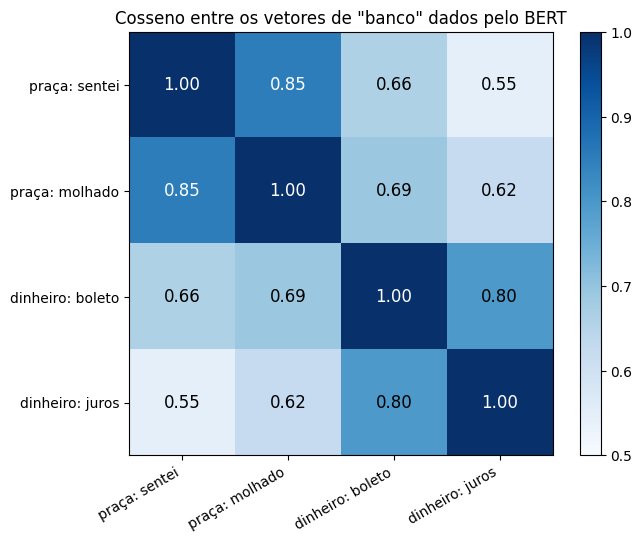

In [ ]:
import torch                                   # a biblioteca de redes neurais que roda o BERT por baixo
from transformers import AutoModel

bert = AutoModel.from_pretrained(nome_bert)    # o BERTimbau "puro", que devolve os vetores (sem a tarefa de [MASK])

def vetor_da_palavra(frase, palavra):
    entrada = tokenizador(frase, return_tensors="pt")      # corta em tokens e transforma em números (pt = PyTorch)
    with torch.no_grad():                                  # no_grad: só vamos usar o modelo, não treinar
        saida = bert(**entrada).last_hidden_state[0]       # vetores da última camada: um por token (768 números)
    tokens = tokenizador.convert_ids_to_tokens(entrada["input_ids"][0])   # os tokens, para achar a posição
    posicao = tokens.index(palavra)                        # em que posição está a palavra procurada
    return saida[posicao].numpy()                          # o vetor dessa posição, como array do NumPy

frases_banco = [
    "Sentei no banco da praça para descansar.",
    "O banco da praça estava molhado de chuva.",
    "Fui ao banco pagar um boleto.",
    "O banco aumentou os juros do empréstimo.",
]
vetores_banco = [vetor_da_palavra(f, "banco") for f in frases_banco]   # um vetor de "banco" por frase

# compara cada vetor com todos os outros, usando a função cosseno da seção 1.6
tabela = [[cosseno(v1, v2) for v2 in vetores_banco] for v1 in vetores_banco]
rotulos = ["praça: sentei", "praça: molhado", "dinheiro: boleto", "dinheiro: juros"]

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(tabela, cmap="Blues", vmin=0.5, vmax=1)                # cor mais escura = mais parecido
ax.set_xticks(range(4)); ax.set_xticklabels(rotulos, rotation=30, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(rotulos)
for i in range(4):                                                    # escreve o número dentro de cada quadrado
    for j in range(4):
        ax.text(j, i, f"{tabela[i][j]:.2f}", ha="center", va="center",
                color="white" if tabela[i][j] > 0.8 else "black", fontsize=12)
ax.set_title('Cosseno entre os vetores de "banco" dados pelo BERT')
plt.colorbar(im)
plt.show()

Leia a matriz como as matrizes da Sessão 7:

- **mesmo sentido**: "banco" de praça com "banco" de praça dá **0,85**, e "banco" de dinheiro com "banco" de dinheiro dá **0,80**;
- **sentidos diferentes**: os cruzamentos ficam entre **0,55 e 0,69**.

É a **mesma palavra**, com as mesmas letras, mas o BERT deu vetores diferentes conforme a frase, e os vetores do mesmo sentido ficaram mais parecidos entre si. No Word2Vec, essa matriz teria **1,00 em todos os quadrados**, porque "banco" tem um vetor só.

(Os valores não chegam perto de zero porque, além do sentido, os vetores guardam outras coisas em comum: é a mesma palavra, um substantivo, na mesma posição da frase.)

## 2.8 O BERT na base de emoções da Sessão 7

Será que esses vetores ajudam a classificar? Vamos repetir o experimento da Sessão 7, com a **mesma divisão** treino/teste (80/20, `random_state=42`, estratificada), trocando só o jeito de transformar a frase em números:

- **Sessão 7:** TF-IDF (uma coluna por palavra) + SVM linear;
- **Hoje:** cada frase vira a **média dos vetores do BERT** de todos os seus tokens (768 números) + regressão logística.

O BERT entra aqui como **extrator de características**: não mexemos nos pesos dele, só usamos os vetores. (O passo seguinte, que não cabe hoje, seria o *fine-tuning*: continuar o treino do BERT inteiro com as nossas frases.)

A célula abaixo passa as frases pelo BERT em lotes de 32. No Colab sem GPU leva cerca de um minuto.

In [ ]:
def vetores_das_frases(frases, lote=32):
    resultado = []                                          # um bloco de vetores por lote
    for i in range(0, len(frases), lote):                   # range com passo 32: 0, 32, 64, ...
        pedaco = frases[i:i + lote]                         # as 32 frases deste lote
        # padding=True completa as frases curtas com tokens vazios para todas terem o mesmo tamanho
        entrada = tokenizador(pedaco, padding=True, truncation=True, return_tensors="pt")
        with torch.no_grad():
            saida = bert(**entrada).last_hidden_state       # formato: (frases, tokens, 768)
        # attention_mask vale 1 nos tokens de verdade e 0 nos de enchimento
        mascara = entrada["attention_mask"].unsqueeze(-1)   # unsqueeze(-1) acerta o formato para multiplicar
        # média só dos tokens de verdade: soma (vetor x máscara) e divide pelo número de tokens
        media = (saida * mascara).sum(dim=1) / mascara.sum(dim=1)
        resultado.append(media.numpy())
    return np.vstack(resultado)                             # vstack empilha os blocos numa matriz só

X_bert = vetores_das_frases(emocoes["frase"].tolist())
print("Formato:", X_bert.shape, "-> uma linha por frase, 768 números por linha")

Formato: (909, 768) -> uma linha por frase, 768 números por linha


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

y = emocoes["sentimento"]
# a mesma divisão da Sessão 7; dividimos as POSIÇÕES das frases para usar nas duas representações
pos_treino, pos_teste = train_test_split(np.arange(len(emocoes)), test_size=0.2, random_state=42, stratify=y)
y_treino, y_teste = y.iloc[pos_treino], y.iloc[pos_teste]   # iloc pega as linhas por posição

# 1) Sessão 7: TF-IDF + SVM linear
tfidf = TfidfVectorizer()
X_tr = tfidf.fit_transform(emocoes["frase"].iloc[pos_treino])     # aprende o vocabulário só no treino
X_te = tfidf.transform(emocoes["frase"].iloc[pos_teste])
pred_tfidf = SVC(kernel="linear").fit(X_tr, y_treino).predict(X_te)

# 2) Hoje: vetores do BERT + regressão logística (max_iter=2000: deixa o treino ir até o fim)
pred_bert = LogisticRegression(max_iter=2000).fit(X_bert[pos_treino], y_treino).predict(X_bert[pos_teste])

resultado = pd.DataFrame({
    "acurácia": [accuracy_score(y_teste, pred_tfidf), accuracy_score(y_teste, pred_bert)],
    "F1 macro": [f1_score(y_teste, pred_tfidf, average="macro"), f1_score(y_teste, pred_bert, average="macro")],
}, index=["TF-IDF + SVM (Sessão 7)", "BERTimbau + regressão logística"]).round(3)
resultado

,acurácia,F1 macro
TF-IDF + SVM (Sessão 7),0.681,0.677
BERTimbau + regressão logística,0.852,0.850


**De 68% para 85% de acurácia**, mudando só a representação das frases. O classificador em cima é até mais simples (uma regressão logística).

Por que tanta diferença?

- O TF-IDF só conhece as palavras das **727 frases de treino**. Uma palavra nova vale zero, e "ótimo" e "excelente" são colunas sem relação.
- O BERT chegou já tendo lido **bilhões de palavras**. O vetor de cada frase traz sinônimos, ordem das palavras, negação ("não estou feliz") e contexto.

Dois cuidados, lembrando a Sessão 7:

1. É **uma divisão** treino/teste só. Para uma conclusão firme, o certo seria repetir com validação cruzada, como na Sessão 7. A diferença aqui é grande o suficiente para não ser sorte.
2. **Custo:** o TF-IDF roda em milissegundos em qualquer computador; o BERT tem 110 milhões de pesos e levou cerca de um minuto só para transformar 909 frases curtas. Em produção, com milhões de textos, essa conta pesa.

In [ ]:
# frases novas, com palavras que podem nunca ter aparecido no treino
novas = [
    "Que dia espetacular, estou radiante!",
    "Esse lugar me dá calafrios.",
    "Não aguento mais essa injustiça, que absurdo!",
    "Sinto uma saudade enorme dela.",
    "Não estou nada feliz com isso.",
    "Estou com fome!",
    "Não quero mais trabalhar hoje",
    "Se não fizer meu trabalho direito, vou ser demitida",
    "Não aguendo mais essa pressão",
    "Esse trabalho está me matando",
    "Essas luzes de natal são encantadoras"
]
X_novas_tfidf = tfidf.transform(novas)                       # TF-IDF com o vocabulário do treino
X_novas_bert = vetores_das_frases(novas)                     # vetores do BERT
svm = SVC(kernel="linear").fit(X_tr, y_treino)               # os mesmos dois modelos de antes
logistica = LogisticRegression(max_iter=2000).fit(X_bert[pos_treino], y_treino)
pd.DataFrame({"frase": novas,
              "TF-IDF + SVM": svm.predict(X_novas_tfidf),
              "BERTimbau": logistica.predict(X_novas_bert)})

,frase,TF-IDF + SVM,BERTimbau
0,"Que dia espetacular, estou radiante!",alegria,alegria
1,Esse lugar me dá calafrios.,raiva,medo
2,"Não aguento mais essa injustiça, que absurdo!",raiva,raiva
3,Sinto uma saudade enorme dela.,tristeza,tristeza
4,Não estou nada feliz com isso.,medo,tristeza
5,Estou com fome!,medo,alegria
6,Não quero mais trabalhar hoje,alegria,tristeza
7,"Se não fizer meu trabalho direito, vou ser dem...",medo,medo
8,Não aguendo mais essa pressão,raiva,raiva
9,Esse trabalho está me matando,medo,medo


- **"Esse lugar me dá calafrios."**: "calafrios" não aparece nas frases de treino. O TF-IDF não tem o que usar e chuta **raiva**; o BERT sabe que calafrio tem a ver com **medo**.
- **"Não estou nada feliz com isso."**: o TF-IDF responde **medo**; o BERT responde **tristeza**, que é mais razoável. O BERT lê "não" e "nada" junto com "feliz".
- Nas frases com palavras conhecidas ("injustiça", "saudade", "espetacular... radiante"), os dois acertam.

---
# Parte 3 — Reconhecimento de Entidades Nomeadas (NER)

## 3.1 O que é uma entidade nomeada

**Entidades nomeadas** são os "nomes próprios" do texto: pessoas, lugares, organizações, e também datas, valores, leis, processos... **NER** (*Named Entity Recognition*, reconhecimento de entidades nomeadas) é a tarefa de **encontrar** esses trechos e dizer **de que tipo** eles são.

> *O ministro **Fernando Haddad** <sub>PESSOA</sub> visitou a **Fatec Itaquera** <sub>ORGANIZAÇÃO</sub> em **São Paulo** <sub>LOCAL</sub>.*

Para que serve:

- **Anonimizar documentos** (LGPD): trocar nomes de pessoas por `[PESSOA]` antes de publicar uma decisão judicial ou compartilhar dados;
- **Buscar e organizar**: "todas as notícias que citam a Petrobras", "todos os processos que citam a Lei 8.078";
- **Extrair conhecimento**: montar uma tabela de quem fez o quê, onde e quando, a partir de milhares de textos;
- **Chatbots**: entender que em "quero uma passagem para Recife no dia 3" o destino é Recife e a data é dia 3.

NER é diferente da **classe gramatical** (POS) das Sessões 3-4: o POS diz que "São" e "Paulo" são nomes próprios (PROPN); o NER diz que **"São Paulo", junto**, é **um lugar**.

## 3.2 NER com o spaCy

O `pt_core_news_sm` já tem um componente de NER. Os tipos de entidade que ele conhece:

In [ ]:
import spacy
from spacy import displacy                       # displacy desenha as entidades coloridas no texto

nlp = spacy.load("pt_core_news_sm")              # o mesmo modelo das Sessões 3-4
print("Etapas do modelo:", nlp.pipe_names)       # o NER é a etapa "ner"
print("Tipos de entidade:", nlp.get_pipe("ner").labels)

Etapas do modelo: ['tok2vec', 'morphologizer', 'parser', 'lemmatizer', 'attribute_ruler', 'ner']
Tipos de entidade: ('LOC', 'MISC', 'ORG', 'PER')


- `PER`: pessoa;
- `LOC`: local (cidade, estado, país, bairro...);
- `ORG`: organização (empresa, órgão público, time...);
- `MISC`: miscelânea, isto é, outros nomes próprios que não se encaixam nos três primeiros (eventos, obras, leis...).

O NER do `pt_core_news_sm` foi treinado com o **WikiNER**: textos da Wikipédia em português com as entidades marcadas automaticamente a partir dos links entre artigos. Ele acerta cerca de 88% (F1) em textos parecidos com os da Wikipédia. Guarde essa informação: ela vai explicar os erros daqui a pouco.

In [ ]:
texto = ("O presidente Luiz Inácio Lula da Silva se reuniu com o ministro Fernando Haddad em Brasília "
         "para discutir o orçamento da Petrobras. Depois, o ministro visitou a Fatec Mauá, no ABC Paulista para indicar alunos para serem contratados")
doc = nlp(texto)                                 # roda todas as etapas do spaCy, inclusive o NER

for ent in doc.ents:                             # doc.ents: as entidades encontradas
    # ent.text = o trecho; ent.label_ = o tipo; start_char/end_char = onde começa e termina no texto
    print(f"{ent.text:<30} {ent.label_:<5} (caracteres {ent.start_char} a {ent.end_char})")

# style="ent" pinta as entidades; jupyter=True mostra o desenho dentro do notebook
displacy.render(doc, style="ent", jupyter=True)

Luiz Inácio Lula da Silva      PER   (caracteres 13 a 38)
Fernando Haddad                PER   (caracteres 64 a 79)
Brasília                       LOC   (caracteres 83 a 91)
Petrobras                      ORG   (caracteres 121 a 130)
Fatec Mauá                     ORG   (caracteres 161 a 171)
ABC Paulista                   LOC   (caracteres 176 a 188)


Acertou as pessoas (Lula, Haddad), o lugar (Brasília, Zona Leste de São Paulo) e a empresa (Petrobras), cada uma com o trecho completo, mesmo quando a entidade tem várias palavras ("Luiz Inácio Lula da Silva").

Mas errou **"Fatec Itaquera"**, marcada como **pessoa**. O modelo nunca viu "Fatec" na Wikipédia; "Fatec Itaquera" tem cara de nome e sobrenome (duas palavras com letra maiúscula), e ele chutou PER.

## 3.3 Por dentro: NER é classificar cada token

Como um modelo marca um trecho de várias palavras, como "Fatec Itaquera"? Ele transforma o problema numa **classificação de cada token**, com as etiquetas **BIO**:

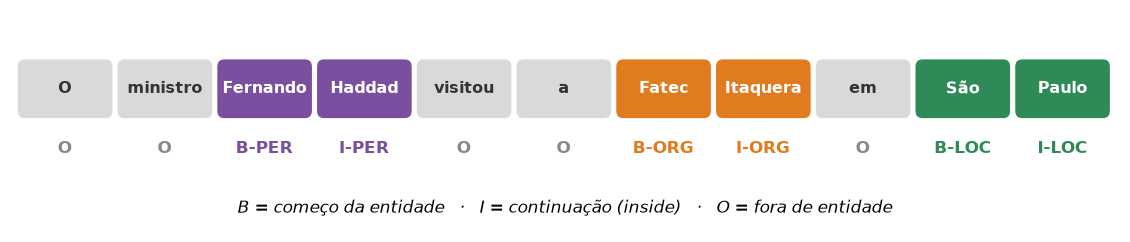

- **B**-tipo (*begin*): o token **começa** uma entidade daquele tipo;
- **I**-tipo (*inside*): o token **continua** a entidade que começou antes;
- **O** (*outside*): o token está **fora** de qualquer entidade.

Ou seja, NER é um problema de **classificação supervisionada**, como os da Sessão 7, só que com uma previsão por token em vez de uma por frase. Alguém precisou anotar milhares de frases token por token para treinar o modelo. A figura mostra o **gabarito** (o que uma pessoa marcaria). O spaCy mostra as etiquetas que **ele** previu em `token.ent_iob_` e `token.ent_type_`:

In [ ]:
linhas = []
for token in nlp("O ministro Fernando Haddad visitou a Fatec Itaquera em São Paulo."):                        # percorre os tokens da frase
    # ent_iob_ dá B, I ou O; ent_type_ dá o tipo (vazio quando é O)
    etiqueta = token.ent_iob_ + ("-" + token.ent_type_ if token.ent_type_ else "")
    linhas.append({"token": token.text, "etiqueta BIO": etiqueta})
pd.DataFrame(linhas).T                              # .T deita a tabela: uma coluna por token

,0,1,2,3,4,5,6,7,8,9,10,11
token,O,ministro,Fernando,Haddad,visitou,a,Fatec,Itaquera,em,São,Paulo,.
etiqueta BIO,O,O,B-PER,I-PER,O,O,B-PER,I-PER,O,B-LOC,I-LOC,O


## 3.4 NER nas ementas dos projetos de lei

Vamos rodar o NER nas 1.599 ementas e contar as entidades mais frequentes de cada tipo. O `nlp.pipe` processa uma lista de textos de uma vez, mais rápido do que chamar `nlp` um por um:

In [ ]:
from collections import Counter

# nlp.pipe processa todas as ementas; list() guarda os resultados
docs_leis = list(nlp.pipe(leis["ementa"].tolist()))

# conta cada par (texto da entidade, tipo) em todas as ementas
contagem_ents = Counter((ent.text, ent.label_) for doc in docs_leis for ent in doc.ents)

for tipo in ["PER", "LOC", "ORG", "MISC"]:                                # um tipo por vez
    # most_common() ordena da mais frequente para a menos; filtramos só as do tipo da vez
    do_tipo = [(texto, n) for (texto, t), n in contagem_ents.most_common() if t == tipo][:10]
    print(f"{tipo:>4}:", "; ".join(f"{texto} ({n})" for texto, n in do_tipo))

 PER: Código Penal (86); Confere (17); Bases da Educação Nacional (11); Autoriza o Poder Executivo (9); “Dispõe (9); Veda (6); “ (5); Adolescente (5); Herpes Zoster (4); Pelé (3)
 LOC: Lei (282); Decreto-Lei (263); Institui (72); Confere (62); Município (49); Livro dos Heróis (41); Brasil (18); Estado de Minas Gerais (17); Estado de Santa Catarina (13); Estado do Rio Grande do Sul (12)
 ORG: SUS (64); Sistema Único de Saúde (21); Fundo de Garantia do Tempo de Serviço (6); Constituição Federal (6); Ministério Público (5); FGTS (5); TEA (5); Fundo de Manutenção e Desenvolvimento da Educação Básica (4); Política Nacional de Prevenção e Controle do Câncer (4); Fundo de Financiamento Estudantil (3)
MISC: Código Penal (98); Lei (73); Código de Trânsito Brasileiro (70); Consolidação das Leis do Trabalho (61); Sistema Único de Saúde (54); Heroínas da Pátria (47); Código de Processo Penal (47); CLT (40); Código Penal Brasileiro (21); Lei nº 9.503 (16)


Aqui o spaCy pequeno sofre. Leia a lista com olhar crítico:

- **Acertos:** SUS e Sistema Único de Saúde como organização; Estado de Minas Gerais, Santa Catarina e Rio Grande do Sul como local; Pelé como pessoa.
- **"Código Penal" como PESSOA (86 vezes)**: de novo, duas palavras com maiúscula têm cara de nome de gente.
- **"Lei" e "Decreto-Lei" como LOCAL (mais de 500 vezes)**, e verbos como **"Institui", "Confere", "Veda"** como local ou pessoa. Toda ementa começa com um verbo com letra maiúscula ("Institui...", "Altera..."), e o modelo confunde maiúscula com nome próprio.
- **O mesmo trecho com tipos diferentes**: "Código Penal" aparece como PER (86) e como MISC (98), dependendo da frase.

O motivo é o que vimos na seção 3.2: o modelo foi treinado com **Wikipédia**, e ementas de lei são um **gênero de texto** muito diferente. É o mesmo problema da Sessão 7: um modelo vai bem nos dados parecidos com os de treino e mal nos diferentes.

In [ ]:
for i in [2, 30, 41, 1000]:                        # algumas ementas para olhar de perto
    displacy.render(docs_leis[i], style="ent", jupyter=True)

Nas quatro ementas:

1. **Pelé**: acertou as duas pessoas, mas "Livro dos Heróis" virou **local**.
2. **Código Penal**: "Decreto-Lei" virou **local** e "Código Penal" virou **pessoa**.
3. **LDB**: "Lei" virou **local**, e o nome da lei foi partido em dois, com "Bases da Educação Nacional" como **pessoa**.
4. **Capital do Crochê**: acertou "Inconfidentes" e "Estado de Minas Gerais", mas marcou "Município" sozinho e "Capital Nacional do Crochê" como local (é um título, não um lugar).

## 3.5 Ensinando regras ao spaCy: `EntityRuler`

Quando sabemos exatamente o formato de uma entidade, não precisamos de aprendizado de máquina: uma **regra** resolve. Toda referência a lei, numa ementa, tem o formato "Lei nº 9.394, de 20 de dezembro de 1996". O `EntityRuler` do spaCy deixa escrever padrões de tokens, parecidos com as expressões regulares das Sessões 3-4, e criar um tipo novo de entidade, `LEI`.

Cada padrão é uma lista: **um dicionário por token**, dizendo como aquele token tem que ser.

In [ ]:
regras = nlp.add_pipe("entity_ruler", before="ner")   # before="ner": as regras rodam antes do modelo e têm prioridade

numero = {"TEXT": {"REGEX": r"^\d[\d.]*(/\d+)?$"}}            # um número como 9.394 ou 12.764/12
n_o = {"LOWER": {"REGEX": r"^n\.?[º°o]?\.?$"}}                 # "nº", "n°", "n.º", "nº." ...
grau = {"TEXT": {"IN": ["º", "°", "."]}, "OP": "?"}             # OP "?" = este token pode aparecer ou não
padroes = [
    # "Lei nº 9.394", "Lei n.º 12.764/12"
    {"label": "LEI", "pattern": [{"LOWER": "lei"}, n_o, grau, numero]},
    # "Lei Complementar nº 101"
    {"label": "LEI", "pattern": [{"LOWER": "lei"}, {"LOWER": "complementar"}, n_o, grau, numero]},
    # "Decreto-Lei nº 2.848" (o spaCy pode manter "Decreto-Lei" como um token só ou separar o hífen)
    {"label": "LEI", "pattern": [{"LOWER": "decreto-lei"}, n_o, grau, numero]},
    {"label": "LEI", "pattern": [{"LOWER": "decreto"}, {"ORTH": "-"}, {"LOWER": "lei"}, n_o, grau, numero]},
    # os códigos mais citados, escritos por extenso
    {"label": "LEI", "pattern": [{"LOWER": "código"}, {"LOWER": {"IN": ["penal", "civil"]}}]},
    {"label": "LEI", "pattern": [{"LOWER": "código"}, {"LOWER": "de"}, {"LOWER": "processo"}, {"LOWER": "penal"}]},
    {"label": "LEI", "pattern": [{"LOWER": "código"}, {"LOWER": "de"}, {"LOWER": {"IN": ["trânsito", "transito"]}}, {"LOWER": "brasileiro"}]},
    {"label": "LEI", "pattern": [{"LOWER": "consolidação"}, {"LOWER": "das"}, {"LOWER": "leis"}, {"LOWER": "do"}, {"LOWER": "trabalho"}]},
]
regras.add_patterns(padroes)                          # entrega os padrões ao EntityRuler

doc = nlp(leis["ementa"][30])               # a mesma ementa de antes, agora com as regras
displacy.render(doc, style="ent", jupyter=True)

In [ ]:
# quantas referências a leis existem nas ementas?
docs_leis = list(nlp.pipe(leis["ementa"].tolist()))            # roda de novo, agora com as regras
leis_citadas = Counter(ent.text for doc in docs_leis for ent in doc.ents if ent.label_ == "LEI")
print("Referências a leis encontradas:", sum(leis_citadas.values()))
pd.DataFrame(leis_citadas.most_common(10), columns=["lei citada", "vezes"])

Referências a leis encontradas: 1197


,lei citada,vezes
0,Código Penal,212
1,Decreto-Lei nº 2.848,156
2,Lei nº 9.503,74
3,Código de Trânsito Brasileiro,72
4,Consolidação das Leis do Trabalho,62
5,Lei nº 9.394,59
6,Código de Processo Penal,49
7,Decreto-Lei nº 3.689,37
8,Lei nº 8.080,32
9,Decreto-Lei nº 5.452,28


Com oito padrões, o spaCy passou a reconhecer **1.197 referências a leis** nas ementas. A tabela mostra as mais citadas, e dá para ler a pauta da Câmara nela: Código Penal (Decreto-Lei nº 2.848), Código de Trânsito (Lei nº 9.503), CLT (Decreto-Lei nº 5.452), LDB (Lei nº 9.394), Código de Processo Penal (Decreto-Lei nº 3.689), Lei do SUS (Lei nº 8.080).

**Regra × aprendizado de máquina:**

- **Regras** são ótimas quando o formato é fixo e conhecido (números de lei, CPF, CEP, datas): são exatas, rápidas e fáceis de explicar. Mas só acham o que alguém pensou em escrever: "Lei Maria da Penha" não tem número e escapa.
- **Modelos** generalizam para casos que ninguém previu, mas erram de jeitos inesperados ("Código Penal" como pessoa).

Na prática, os sistemas reais costumam **juntar os dois**, como fizemos: regras para o que é previsível e o modelo para o resto.

## 3.6 NER com um BERT treinado em textos jurídicos

O spaCy pequeno foi treinado com textos gerais. Para textos jurídicos existe o **LeNER-Br** (Luz de Araujo e colegas, UnB, 2018): 70 documentos jurídicos brasileiros (decisões de tribunais e leis) anotados à mão, token por token, com seis tipos de entidade:

| etiqueta | o que é |
|---|---|
| `PESSOA` | nomes de pessoas |
| `ORGANIZACAO` | tribunais, órgãos, empresas |
| `LOCAL` | lugares |
| `TEMPO` | datas |
| `LEGISLACAO` | leis, decretos, códigos |
| `JURISPRUDENCIA` | decisões de tribunais citadas |

Pierre Guillou pegou o **BERTimbau** e continuou o treino dele com o LeNER-Br para classificar cada token com as etiquetas BIO (isso é o *fine-tuning* que mencionamos na seção 2.8). O modelo está no Hugging Face. O `aggregation_strategy="first"` junta os pedaços de palavra (`##`) e as etiquetas B-/I- numa entidade só.

In [ ]:
# "token-classification" = uma classe para cada token (é o NER); baixa cerca de 400 MB na primeira vez
ner_juridico = pipeline("token-classification",
                        model="pierreguillou/ner-bert-base-cased-pt-lenerbr",
                        aggregation_strategy="first")     # junta os pedaços (##) e os tokens B-/I- da mesma entidade

def compara_ner(texto):
    print(texto, "\n")
    # spaCy (com as regras da seção 3.5)
    print("  spaCy:", [(ent.text, ent.label_) for ent in nlp(texto).ents])
    # BERT jurídico: cada resultado é um dicionário com "word" (o trecho) e "entity_group" (o tipo)
    # start e end dizem onde a entidade começa e termina; texto[start:end] recorta o trecho original
    print("  BERT :", [(texto[r["start"]:r["end"]], r["entity_group"]) for r in ner_juridico(texto)])
    print()

for i in [30, 300, 1000, 2]:                                  # as mesmas ementas para os dois modelos
    compara_ner(leis["ementa"][i])

config.json:   0%|          | 0.00/1.54k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  433MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/561 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/438k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Altera o Decreto-Lei nº. 2.848, de 7 de dezembro de 1940 - Código Penal, para tornar homicídio qualificado o crime praticado contra mais de um membro da mesma família (familicídio), entre outras disposições. 

  spaCy: [('Decreto-Lei nº. 2.848', 'LEI'), ('Código Penal', 'LEI')]
  BERT : [('Decreto', 'LEGISLACAO'), ('-', 'LEGISLACAO'), ('Lei nº. 2.848', 'LEGISLACAO'), ('7 de dezembro de 1940', 'TEMPO'), ('Código', 'LEGISLACAO'), ('Penal', 'TEMPO')]

Altera a Lei n.º 12.764/12, que dispõe sobre a Política Nacional de Proteção dos Direitos da Pessoa com Transtorno do Espectro Autista. 

  spaCy: [('Lei n.º 12.764/12', 'LEI'), ('Política Nacional de Proteção dos Direitos da Pessoa com Transtorno do Espectro Autista', 'ORG')]
  BERT : [('Lei n.º 12.764/12', 'LEGISLACAO')]

Concede ao Município de Inconfidentes, no Estado de Minas Gerais, o título de Capital Nacional do Crochê. 

  spaCy: [('Município', 'LOC'), ('Inconfidentes', 'LOC'), ('Estado de Minas Gerais', 'LOC'), ('Capital Nacional d

Compare os dois modelos ementa por ementa:

- **Lei n.º 12.764/12** e **Capital do Crochê**: o BERT jurídico acerta tudo e, principalmente, **não inventa** entidades. "Município de Inconfidentes" sai inteiro, como LOCAL, e "Capital Nacional do Crochê" fica de fora, como deve ser.
- **Pelé**: as duas pessoas certas, e "Livro dos Heróis" fica de fora (não é nenhum dos seis tipos).
- **Código Penal**: aqui o BERT tropeça. Ele pegou a data (`7 de dezembro de 1940`, TEMPO) e a lei, mas deu B- (começo) para "Decreto", para "-" e para "Lei", partindo uma entidade em três. E marcou "Penal" como **TEMPO**, provavelmente porque vem logo depois da data. É o erro **por token** da seção 3.3: cada token recebe a sua etiqueta, e às vezes elas não combinam entre si.

Nessa ementa, as **regras** do spaCy (seção 3.5) foram melhores do que o BERT. De novo: nenhum método ganha sempre, e por isso se mede (seção 3.7).

**Por que o BERT jurídico vai melhor no geral?** Dois motivos que já vimos hoje: o BERTimbau chegou sabendo português (Parte 2), e o ajuste foi feito com **textos do mesmo gênero** (documentos jurídicos), não com Wikipédia.

## 3.7 Como avaliar um NER

As métricas são as da Sessão 7, **precisão, recall e F1**, mas contadas por **entidade inteira**: o modelo só acerta se encontrar o trecho exato **e** o tipo certo. Achar "Fatec" quando a entidade era "Fatec Itaquera" conta como erro.

- **Precisão:** das entidades que o modelo marcou, quantas estavam certas?
- **Recall:** das entidades que existiam no texto (o gabarito anotado por uma pessoa), quantas o modelo encontrou?

In [ ]:
# gabarito: o que uma pessoa marcaria na frase (trecho, tipo)
gabarito = {("Fernando Haddad", "PER"), ("Fatec Itaquera", "ORG"), ("São Paulo", "LOC"), ("USP", "ORG")}
frase = "O ministro Fernando Haddad visitou a Fatec Itaquera, em São Paulo, com a reitora da USP."
previsto = {(ent.text, ent.label_) for ent in nlp(frase).ents if ent.label_ in {"PER", "LOC", "ORG"}}

acertos = gabarito & previsto                     # & = interseção: o que está nos dois conjuntos
precisao = len(acertos) / len(previsto)           # dos marcados, quantos certos
recall = len(acertos) / len(gabarito)             # dos que existiam, quantos encontrados
f1 = 2 * precisao * recall / (precisao + recall) if acertos else 0.0   # média harmônica (Sessão 7)

print("Previsto pelo spaCy:", previsto)
print("Acertos            :", acertos)
print("Faltaram           :", gabarito - previsto)     # - = diferença: no gabarito, mas não no previsto
print("Marcados a mais    :", previsto - gabarito)
print(f"Precisão = {precisao:.2f} | Recall = {recall:.2f} | F1 = {f1:.2f}")

Previsto pelo spaCy: {('São Paulo', 'LOC'), ('Fatec Itaquera', 'PER'), ('USP', 'LOC'), ('Fernando Haddad', 'PER')}
Acertos            : {('São Paulo', 'LOC'), ('Fernando Haddad', 'PER')}
Faltaram           : {('Fatec Itaquera', 'ORG'), ('USP', 'ORG')}
Marcados a mais    : {('Fatec Itaquera', 'PER'), ('USP', 'LOC')}
Precisão = 0.50 | Recall = 0.50 | F1 = 0.50


O spaCy marcou 4 entidades e acertou 2 (**precisão 0,50**); das 4 que existiam, encontrou 2 (**recall 0,50**).

Repare que os dois erros contam **duas vezes**: "Fatec Itaquera" como PER é uma entidade marcada a mais (piora a precisão) **e** uma entidade ORG que faltou (piora o recall). O trecho estava certo, mas o tipo errado, e na avaliação por entidade isso é erro.

Para avaliar de verdade, faz-se essa conta em centenas de frases anotadas à mão. É assim que se chega aos números dos modelos: cerca de 0,88 de F1 para o spaCy no WikiNER e cerca de 0,89 para o BERT jurídico no LeNER-Br, segundo as páginas dos modelos. Cada um foi medido **no seu próprio tipo de texto**. Nas ementas, como vimos, o spaCy ficaria bem abaixo disso.

## 3.8 Aplicação: anonimizar um texto

Juntando tudo: trocar cada pessoa por `[PESSOA]`, como um tribunal faz antes de publicar uma decisão. Trocamos de trás para frente, para que as posições das entidades que ainda faltam não mudem.

In [ ]:
def anonimizar(texto, tipos=("PESSOA",)):
    entidades = ner_juridico(texto)                               # as entidades que o BERT jurídico encontrou
    # sorted(..., reverse=True) ordena pela posição de início, da última para a primeira
    for ent in sorted(entidades, key=lambda e: e["start"], reverse=True):
        if ent["entity_group"] in tipos:                          # só os tipos que queremos esconder
            # texto[:início] + marcador + texto[fim:] substitui o trecho da entidade
            texto = texto[:ent["start"]] + f"[{ent['entity_group']}]" + texto[ent["end"]:]
    return texto

# texto inventado para a aula (nomes fictícios)
decisao = ("O juiz João Carlos Pereira, da 2ª Vara Cível de Campinas, condenou a empresa Alfa Transportes Ltda. "
           "a indenizar Maria Aparecida dos Santos em R$ 10.000,00, com base no Código de Defesa do Consumidor, "
           "em 15 de março de 2023.")
print(decisao, "\n")
# as entidades que o modelo encontrou: (trecho, tipo)
print([(decisao[r["start"]:r["end"]], r["entity_group"]) for r in ner_juridico(decisao)], "\n")
print(anonimizar(decisao))
print(anonimizar(decisao, tipos=("PESSOA", "LOCAL", "TEMPO")))

O juiz João Carlos Pereira, da 2ª Vara Cível de Campinas, condenou a empresa Alfa Transportes Ltda. a indenizar Maria Aparecida dos Santos em R$ 10.000,00, com base no Código de Defesa do Consumidor, em 15 de março de 2023. 

[('João Carlos Pereira', 'PESSOA'), ('2ª Vara Cível de Campinas', 'ORGANIZACAO'), ('Alfa Transportes Ltda.', 'ORGANIZACAO'), ('Maria Aparecida dos Santos', 'PESSOA'), ('Código de Defesa do Consumidor', 'LEGISLACAO'), ('15 de março de 2023', 'TEMPO')] 

O juiz [PESSOA], da 2ª Vara Cível de Campinas, condenou a empresa Alfa Transportes Ltda. a indenizar [PESSOA] em R$ 10.000,00, com base no Código de Defesa do Consumidor, em 15 de março de 2023.
O juiz [PESSOA], da 2ª Vara Cível de Campinas, condenou a empresa Alfa Transportes Ltda. a indenizar [PESSOA] em R$ 10.000,00, com base no Código de Defesa do Consumidor, em [TEMPO].


A primeira linha esconde só as pessoas (o juiz e a parte); a segunda esconde também a data. O modelo encontrou as seis entidades do texto: as duas pessoas, a vara, a empresa, o código e a data.

**Cuidado na vida real:** anonimizar com NER **reduz** o trabalho, mas não é garantia. Se o modelo deixar escapar um único nome, o documento vaza. Por isso, em tribunais e empresas, o NER costuma marcar e uma pessoa revisa antes de publicar, a mesma ideia do fim da Sessão 7 (o modelo faz o grosso, a pessoa confere os casos duvidosos).

## 3.9 Bônus: o spaCy também sabe a classe gramatical

Lembra das Sessões 3-4? O mesmo `nlp` que encontra entidades também diz a **classe gramatical** de cada palavra (verbo, preposição, nome próprio...). Isso se chama **POS tagging** (*part-of-speech*, "classe de palavra") e fica em `token.pos_`. Veja as duas coisas lado a lado:

In [ ]:
# nomes em português das etiquetas de classe gramatical
classes = {"NOUN": "substantivo", "PROPN": "nome próprio", "VERB": "verbo", "AUX": "verbo auxiliar",
           "ADJ": "adjetivo", "ADV": "advérbio", "ADP": "preposição", "DET": "artigo/determinante",
           "PRON": "pronome", "CCONJ": "conjunção", "SCONJ": "conjunção", "NUM": "numeral", "PUNCT": "pontuação"}

linhas = []
for token in nlp("O ministro Fernando Haddad visitou a Fatec Itaquera em São Paulo."):   # percorre os tokens
    linhas.append({
        "token": token.text,
        "classe gramatical (POS)": classes.get(token.pos_, token.pos_),   # get: nome em português (ou a etiqueta, se faltar)
        "entidade (NER)": token.ent_iob_ + ("-" + token.ent_type_ if token.ent_type_ else ""),   # BIO, como na seção 3.3
    })
pd.DataFrame(linhas)

O **POS** diz o que cada palavra **é na gramática**: "São" e "Paulo" são dois nomes próprios. O **NER** diz **de que coisa do mundo** o trecho fala: "São Paulo", junto, é um lugar. As duas tarefas são o mesmo tipo de problema: **dar uma etiqueta a cada token**.

---
# Para fechar: do Bag of Words aos LLMs

| | Bag of Words / TF-IDF | Word2Vec | BERT |
|---|---|---|---|
| Uma palavra vira | uma coluna (0 ou contagem) | um vetor fixo (50-300 números) | um vetor que **muda com a frase** (768 números) |
| Sabe que "ótimo" ≈ "excelente"? | não | sim | sim |
| Separa "banco" de praça e de dinheiro? | não | não | sim |
| Ordem das palavras | ignora | só a janela | usa a frase toda (atenção) |
| Como aprende | só conta | adivinha vizinhos (auto-supervisionado) | adivinha palavras tampadas (auto-supervisionado) |
| Custo | quase nenhum | baixo | alto (110 milhões de pesos) |
| Onde vimos | Sessões 5-7 | Parte 1 | Partes 2 e 3 |

As três ideias que ficam:

1. **Significado = contexto.** Palavras que aparecem nos mesmos lugares têm significados parecidos, e o computador aprende isso sozinho, a partir de texto puro.
2. **O próprio texto vira o rótulo.** Adivinhar vizinhos (Word2Vec), palavras tampadas (BERT) ou a próxima palavra (GPT) não precisa de anotação. É isso que permite treinar com bilhões de palavras.
3. **Modelo pré-treinado + ajuste.** Ninguém treina um BERT do zero para cada problema: pega-se um modelo pronto (o BERTimbau) e se usa como extrator de características (seção 2.8) ou se ajusta com poucos exemplos anotados (o NER jurídico da seção 3.6).

O próximo passo dessa história são os modelos tipo GPT, treinados para adivinhar a próxima palavra com **trilhões** de palavras: os LLMs, que vocês vão ver nas aulas de reposição (chat, RAG e agentes).

---
# Exercícios

1. **Contextos.** Use a função `contextos` (seção 1.2) com duas palavras das ementas que você acha que têm significado parecido. Os contextos são parecidos? Confira com `w2v.wv.similarity("palavra1", "palavra2")`.
2. **CBOW × skip-gram.** Treine de novo o Word2Vec das ementas (seção 1.4) com `sg=0` (CBOW). Os vizinhos de "penal" e "saúde" mudam? Qual dos dois parece melhor nesse corpus pequeno?
3. **Vizinhos.** Escolha cinco palavras do seu dia a dia e veja os vizinhos delas no NILC com `nilc.most_similar` (seção 1.5). Algum vizinho é um antônimo, como aconteceu com "feliz" e "triste"? Por que isso acontece?
4. **Lacunas.** Escreva três frases com `[MASK]` (seção 2.6) em que o BERT precise olhar para **depois** da lacuna para acertar. Ele acerta?
5. **Ambiguidade.** Repita a seção 2.7 com a palavra "pena" (a pena do juiz × a pena do pássaro) e depois com "cabo" (o cabo do Exército × o cabo da vassoura). O BERT separa os sentidos? Atenção: a função `vetor_da_palavra` só funciona com palavras que o BERT não quebra em pedaços; "manga", por exemplo, vira `mang` + `##a` (confira com `tokenizador.tokenize("manga")`).
6. **Regras.** Acrescente ao `EntityRuler` (seção 3.5) um padrão para "Constituição Federal" e outro para "Estatuto da Criança e do Adolescente". Quantas ementas citam cada um?
7. **Desafio — avaliação.** Escolha 5 ementas, anote você mesmo as entidades `PESSOA`, `LOCAL` e `ORGANIZACAO` (como na seção 3.7) e calcule precisão, recall e F1 do spaCy e do BERT jurídico. Qual se saiu melhor?

## Para aprofundar

- FIRTH, J. R. A synopsis of linguistic theory, 1930-1955. In: *Studies in Linguistic Analysis*. Oxford: Blackwell, 1957. (Origem da frase "you shall know a word by the company it keeps".)
- MIKOLOV, T.; CHEN, K.; CORRADO, G.; DEAN, J. *Efficient Estimation of Word Representations in Vector Space.* 2013. [arxiv.org/abs/1301.3781](https://arxiv.org/abs/1301.3781)
- HARTMANN, N. et al. *Portuguese Word Embeddings: Evaluating on Word Analogies and Natural Language Tasks.* STIL, 2017. [aclanthology.org/W17-6615](https://aclanthology.org/W17-6615/) (os embeddings do NILC usados na Parte 1: [huggingface.co/nilc-nlp/word2vec-skip-gram-50d](https://huggingface.co/nilc-nlp/word2vec-skip-gram-50d))
- VASWANI, A. et al. *Attention Is All You Need.* 2017. [arxiv.org/abs/1706.03762](https://arxiv.org/abs/1706.03762)
- DEVLIN, J.; CHANG, M.-W.; LEE, K.; TOUTANOVA, K. *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.* NAACL, 2019. [aclanthology.org/N19-1423](https://aclanthology.org/N19-1423/)
- SOUZA, F.; NOGUEIRA, R.; LOTUFO, R. *BERTimbau: pretrained BERT models for Brazilian Portuguese.* BRACIS, 2020. Modelo: [huggingface.co/neuralmind/bert-base-portuguese-cased](https://huggingface.co/neuralmind/bert-base-portuguese-cased)
- LUZ DE ARAUJO, P. H. et al. *LeNER-Br: a Dataset for Named Entity Recognition in Brazilian Legal Text.* PROPOR, 2018. [github.com/peluz/lener-br](https://github.com/peluz/lener-br) (modelo usado na seção 3.6: [huggingface.co/pierreguillou/ner-bert-base-cased-pt-lenerbr](https://huggingface.co/pierreguillou/ner-bert-base-cased-pt-lenerbr))
- Documentação do spaCy sobre entidades: [spacy.io/usage/linguistic-features#named-entities](https://spacy.io/usage/linguistic-features#named-entities) e sobre o `EntityRuler`: [spacy.io/usage/rule-based-matching#entityruler](https://spacy.io/usage/rule-based-matching#entityruler)